# MADT7202 - ScentSelf anchor-note analysis, Update4

Revised 13 October 2026 after review. This is exploratory, not preregistered confirmation. The source data permission issue remains unresolved; no new collection is performed here and raw workbooks are not redistributed.

**Collection:** Selenium, 30 August-12 October 2026, dates confirmed by the author. Fragrantica is the primary source; Parfumo note supplements occur in 11 of the 209 primary records and 36 of the 1,780 wider records. This is field supplementation, not independent triangulation. Inspect `Supplemental Notes Source` in your local workbook. The manifest fixes the 209 selected URLs. The catalogue is purposive and is not representative of market demand.

**What changed:** Both ranks now refer to the surviving nodes in the same graph; ties use average rank (betweenness rounded to 12 decimals). Only strictly positive betweenness can qualify. Whole brands are sampled with replacement; no cluster is truncated. Sample size varies, the minimum frequency scales with that sample size, and the selected absolute edge cutoff stays fixed within bootstrap runs. Absence/zero centrality counts as failure in the denominator of 300.

Set `SCENT_DATA` to the provided local workbook. Start in the repository root or `notebooks/`. Python dependencies are in `requirements.txt`.


In [1]:
import os, sys, json, hashlib, platform
from pathlib import Path
import importlib.metadata as metadata
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import networkx as nx
from corpus import load_corpus
from notes_clean import perfume_note_sets
from decision_rule import apply_rule, analyse, choose_k
DATA = Path(os.environ.get('SCENT_DATA', str(ROOT / 'data/combined.xlsx')))
if not DATA.exists():
    raise FileNotFoundError('Set SCENT_DATA to your local combined workbook; raw data are not bundled.')
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
versions = {name: metadata.version(name) for name in ['pandas','numpy','networkx','scipy','openpyxl','matplotlib']}
versions['python'] = platform.python_version()
provenance = {'collection_start':'2026-08-30', 'collection_end':'2026-10-12',
              'date_basis':'Author confirmation in conversation',
              'snapshot_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest(),
              'manifest_sha256':hashlib.sha256((ROOT/'data/list_209_urls.csv').read_bytes()).hexdigest(),
              'versions':versions}
print(json.dumps(provenance, indent=2))


{
  "collection_start": "2026-08-30",
  "collection_end": "2026-10-12",
  "date_basis": "Author confirmation in conversation",
  "snapshot_sha256": "2a0cece7175d7197fa230573562bd607fe6b85c7563ceeb190051306fce5fd21",
  "manifest_sha256": "c5237e75878a865a00740990d4ba40ddf3a87f4c6c2fc03091356f7afc290ae2",
  "versions": {
    "pandas": "3.0.1",
    "numpy": "2.5.4",
    "networkx": "3.7",
    "scipy": "1.18.1",
    "openpyxl": "3.1.5",
    "matplotlib": "3.11.2",
    "python": "3.12.14"
  }
}


## 1. Input audit and sampling

Original list reconciliation: 216 entries - 3 official-product pages - 7 duplicate page entries + 3 other releases = 209 distinct pages. The committed manifest is the selection authority. It includes the extra releases named in Update3. No team corpus is asserted: the author described this as an individual IS project. The class requirement to differ from the team's industry still needs to be checked against the actual team project.


In [2]:
primary = load_corpus(DATA)
wider = load_corpus(DATA, scope='all')
unsupplemented = load_corpus(DATA, exclude_supplemented=True)
audit = {'primary_n':len(primary),'wider_n':len(wider),
         'primary_supplemented':int(primary['Supplemental Notes Source'].notna().sum()),
         'wider_supplemented':int(wider['Supplemental Notes Source'].notna().sum()),
         'unsupplemented_n':len(unsupplemented),
         'primary_families':primary['Scent Family Primary'].fillna('Unknown').str.split().str[0].value_counts().to_dict()}
assert audit['primary_n']==209 and audit['wider_n']==1780
assert audit['primary_supplemented']==11 and audit['unsupplemented_n']==198
print(json.dumps(audit, indent=2))


{
  "primary_n": 209,
  "wider_n": 1780,
  "primary_supplemented": 11,
  "wider_supplemented": 36,
  "unsupplemented_n": 198,
  "primary_families": {
    "Floral": 61,
    "Oriental": 51,
    "Woody": 38,
    "Aromatic": 24,
    "Citrus": 11,
    "Unknown": 10,
    "Chypre": 10,
    "Leather": 4
  }
}


## 2. Graph construction and revised rule

Node = cleaned declared note. Undirected edge = two notes in one perfume, once per perfume. Whole-perfume co-occurrence is used because the decision concerns a complete fragrance; a same-pyramid-tier window would omit cross-tier combinations. No seed note was used in selecting the list. Notes occurring in >=20% of records are excluded as high-prevalence controls; this does not prove they are semantically generic. Keep frequency >=max(5, round(0.02*N)); remove isolates after edge pruning.

Raw weight counts shared perfumes; weighted shortest-path distance = 1/weight. Choose k in 3..10 nearest density 0.12 after removing isolates (a heuristic inherited from exploratory work); tie picks smaller k. The finite search range may fail to reach 0.12 on the larger corpus.

A candidate needs positive top-10 betweenness, frequency rank minus betweenness rank >=5 on the same nodes, top-10 in >=80% of 300 whole-brand samples (seed 7), and positive top-10 status at k-3, k and k+2. This heuristic does not establish consumer preference or statistical excess centrality. If none passes, the most stable current bridge is an experimental control only. Ties in fallback stability use primary betweenness rank then alphabetical name.


In [3]:
sets = perfume_note_sets(primary)
cutoffs=[]
for k in range(3,11):
    a=analyse(sets,k)
    cutoffs.append({'k':k,'nodes':len(a['graph']),'edges':a['graph'].number_of_edges(),'density':nx.density(a['graph'])})
print(pd.DataFrame(cutoffs).to_string(index=False))
main = apply_rule(primary)
print('Selected k:',main['k'],'; passed:',main['passed'],'; fallback:',main['fallback'])
print(pd.DataFrame(main['rows']).to_string(index=False))


 k  nodes  edges  density
 3     76    268 0.094035
 4     45     99 0.100000
 5     29     48 0.118227
 6     20     23 0.121053
 7     11      9 0.163636
 8      3      2 0.666667
 9      3      2 0.666667
10      2      1 1.000000
Selected k: 6 ; passed: [] ; fallback: Lemon
              note  frequency  frequency_rank  betweenness  betweenness_rank  rank_gap  bootstrap_hits  bootstrap_runs  bootstrap_p  bridge  stable  sweep_all  passed
             Lemon         32             1.5     0.160819               1.0       0.5             262             300     0.873333    True    True       True   False
   Mandarin Orange         32             1.5     0.152047               2.0      -0.5             202             300     0.673333    True   False      False   False
        Tonka Bean         29             3.0     0.111111               3.0       0.0             189             300     0.630000    True   False      False   False
    Orange Blossom         24             7.0     0.0

## 3. Robustness on the full rule, not only bridge membership

NPMI uses the same primary raw cutoff k=6 and additionally NPMI >0.1, with distance 1/NPMI. It may change the graph, ranks and control. The wider corpus includes the primary set and search by-catch; it is a sensitivity analysis, not an independent validation sample. Excluding all 11 supplemented records tests dependence on those records; it does not reconstruct their original unsupplemented note lists and it does not solve data permission.


In [4]:
checks={}
for name, frame, options in [
    ('wider', wider, {}),
    ('npmi', primary, {'weight':'npmi','k':main['k']}),
    ('without_supplemented',unsupplemented,{})]:
    result=apply_rule(frame,**options)
    checks[name]=result
    print(name,': N=',result['N'],'k=',result['k'],'nodes=',result['nodes'],'edges=',result['edges'],
          'passed=',result['passed'],'fallback=',result['fallback'])
    print(pd.DataFrame(result['rows']).head(20).to_string(index=False))
print('PRIMARY CUTOFF SWEEP:',json.dumps(main['sweep']))
for threshold in (0.15,0.25):
    a=analyse(sets,main['k'],generic_thr=threshold)
    print('Prevalence exclusion',threshold,'top-positive bridges:',sorted(a['bridges']))


wider : N= 1780 k= 10 nodes= 80 edges= 529 passed= [] fallback= Orange Blossom
              note  frequency  frequency_rank  betweenness  betweenness_rank  rank_gap  bootstrap_hits  bootstrap_runs  bootstrap_p  bridge  stable  sweep_all  passed
             Cedar        301             1.0     0.447095               1.0       0.0             295             300     0.983333    True    True       True   False
           Vetiver        299             2.0     0.372931               2.0       0.0             282             300     0.940000    True    True       True   False
    Orange Blossom        206             4.0     0.126907               3.0       1.0             297             300     0.990000    True    True       True   False
        Tonka Bean        195             5.0     0.074651               4.0       1.0             217             300     0.723333    True   False       True   False
   Mandarin Orange        232             3.0     0.055826               5.0      -2.0

## 4. Save traceable results

The values below are computed, not copied from Update3. The PDF reads `update4_summary.json`. The full row tables and cutoff sweeps make the choice of control and limitations auditable.


In [5]:
summary={'revision':'Update4','revised_on':'2026-10-13','provenance':provenance,
         'audit':audit,'cutoff_candidates':cutoffs,'primary':main,'checks':checks}
(RESULTS/'update4_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
for name,result in {'primary':main,**checks}.items():
    pd.DataFrame(result['rows']).to_csv(RESULTS/f'update4_{name}_metrics.csv',index=False)
    print(name, ':',len(result['passed']),'qualifying notes; control =',result['fallback'])
print('Outputs saved under results/. Figure is generated by src/figure.py; PDF by report/render.py.')


primary : 0 qualifying notes; control = Lemon
wider : 0 qualifying notes; control = Orange Blossom
npmi : 0 qualifying notes; control = Lemon
without_supplemented : 0 qualifying notes; control = Lemon
Outputs saved under results/. Figure is generated by src/figure.py; PDF by report/render.py.


## 5. Primary graph
Blue denotes strictly positive betweenness. Family colours from Update3 have been removed.

20 23


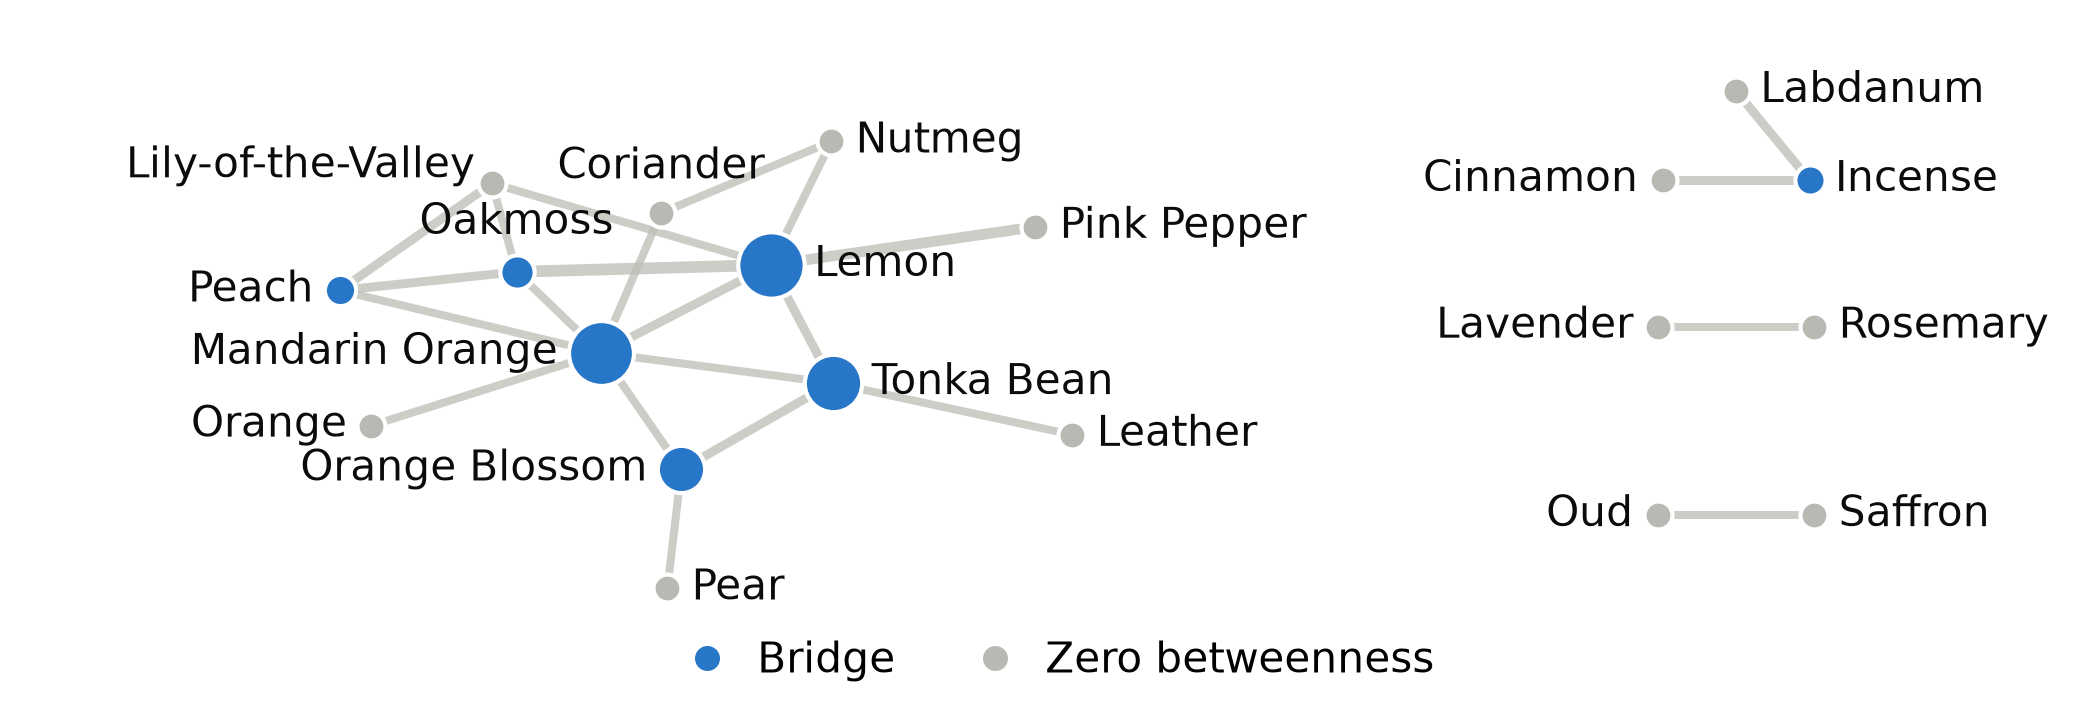

In [6]:
from figure import draw
draw(primary, out=str(RESULTS / 'fig_page.png'))
from IPython.display import Image, display
display(Image(filename=str(RESULTS / 'fig_page.png')))

## Interpretation and remaining conditions

Choose a control from the main curated catalogue only; do not treat its ranking as market-wide superiority. NPMI, the wider corpus and removal of supplemented records can change the control even when no differentiating candidate passes. Co-occurrence of declared notes is not consumer liking or a recipe.

The proposed tester plan in the PDF is a future plan, not a completed experiment. It is conditional on resolving source permission or replacing the input with a permitted dataset and rechecking conclusions. Fragrantica written permission has not been established. Parfumo supplement permission has not been established either. Source acknowledgment and nonpublication of raw data do not grant permission. Original Update3 is preserved in Git history (commit f93a00e4952541e7519eec5eabb8f13402c46c61).
